# Лабораторна робота №3
## Метод найменших квадратів
**Виконав:** Дораж Михайло, ФЕП-31. **Дисципліна:** Методи та технології обчислень.

Номер роботи виправлено на 3 за уточненням студента. Мета - побудувати многочлени найкращого квадратичного наближення для 24 значень температури, порівняти степені 1..10, дослідити похибки та виконати екстраполяцію на три місяці. Джерело даних - приклад із наданого завдання, не окрема метеорологічна база.

## 1. Вхідні дані та реалізація
Повна реалізація алгоритмів міститься у `main.py` поруч із цим блокнотом. Функції `form_matrix` і `form_vector` формують нормальну систему; `gauss_solve` реалізує метод Гауса з вибором головного елемента у стовпці; `polynomial` використовує схему Горнера.

Для чисельної стійкості застосовано лінійну заміну $t=(x-12.5)/11.5$. Вона не змінює простір многочленів заданого степеня.

In [1]:
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from main import read_data, form_matrix, form_vector, gauss_solve, polynomial, variance, calculate, save_outputs, make_plots

BASE = Path.cwd()
x, y = read_data(BASE / "data.csv")
print("Місяць | Температура, °C")
for month, temp in zip(x, y):
    print(f"{month:6.0f} | {temp:9.1f}")

Місяць | Температура, °C
     1 |      -2.0
     2 |       0.0
     3 |       5.0
     4 |      10.0
     5 |      15.0
     6 |      20.0
     7 |      23.0
     8 |      22.0
     9 |      17.0
    10 |      10.0
    11 |       5.0
    12 |       0.0
    13 |     -10.0
    14 |       3.0
    15 |       7.0
    16 |      13.0
    17 |      19.0
    18 |      20.0
    19 |      22.0
    20 |      21.0
    21 |      18.0
    22 |      15.0
    23 |      10.0
    24 |       3.0


## 2. Нормальні рівняння та критерії якості
Для $P_m(t)=\sum_{j=0}^{m} c_jt^j$ нормальна система має вигляд $Bc=C$, де
$B_{ij}=\sum_k t_k^{i+j}$, $C_i=\sum_k y_kt_k^i$.

У теоретичній формулі завдання використано $\delta=\sqrt{\mathrm{SSE}/N}$, а в псевдокоді - $D=\mathrm{SSE}/N$. Виводимо обидва показники: **MSE (°C²)** і **RMSE (°C)**. Мінімізують їх ті самі степені.

In [2]:
result = calculate(BASE / "data.csv")
save_outputs(result, BASE)
make_plots(result, BASE, show=False)
optimal = result["models"][result["optimal_degree"] - 1]
print("Нормальна матриця для m=2:")
t = (x - result["center"]) / result["scale"]
print(form_matrix(t, 2))
print("Вектор правих частин для m=2:")
print(form_vector(t, y, 2))

Лабораторна робота №3. Метод найменших квадратів.
Джерело: 24 значення середньомісячних температур із прикладу завдання.
Кількість вузлів: 24; місяці: 1..24; крок: 1 місяць.
Масштабування: t = (x - 12.5) / 11.5.

 m |     D=MSE, °C² |    delta=RMSE, °C | max|y-P|, °C
 1 |   75.522910628 |       8.690391857 | 21.224202899
 2 |   74.006481707 |       8.602702000 | 22.597391304
 3 |   72.776636769 |       8.530922387 | 22.413043478
 4 |   29.246262373 |       5.407981358 | 15.055797101
 5 |   26.173368455 |       5.115991444 | 14.595474631
 6 |    7.918713247 |       2.814020833 |  9.871623837
 7 |    7.908314731 |       2.812172600 |  9.834695333
 8 |    3.665168204 |       1.914462902 |  7.588518831
 9 |    3.661853232 |       1.913596936 |  7.561669590
10 |    2.843214070 |       1.686183285 |  6.593893927

Оптимальний степінь за мінімумом D: m = 10.
Коефіцієнти P(t) у порядку зростання степеня:
c[0] = -3.4073929786948
c[1] = -13.1850314834044
c[2] = 303.331202370416
c[3] = 69.32046464

Нормальна матриця для m=2:
[[24.          0.          8.69565217]
 [ 0.          8.69565217  0.        ]
 [ 8.69565217  0.          5.65792718]]
Вектор правих частин для m=2:
[266.          28.17391304  86.8241966 ]


## 3. Апроксимація та вибір степеня
Мінімальна MSE серед перевірених моделей досягається при $m=10$: $D=2.843214070$ °C², $\delta=1.686183285$ °C. Максимальна абсолютна вузлова похибка - 6.593893927 °C у місяці 13, де вхідна температура становить -10 °C.

Простори многочленів вкладені один в одного, тому збільшення степеня зазвичай зменшує навчальну похибку. Мінімум на цих даних не перевіряє якість прогнозу.

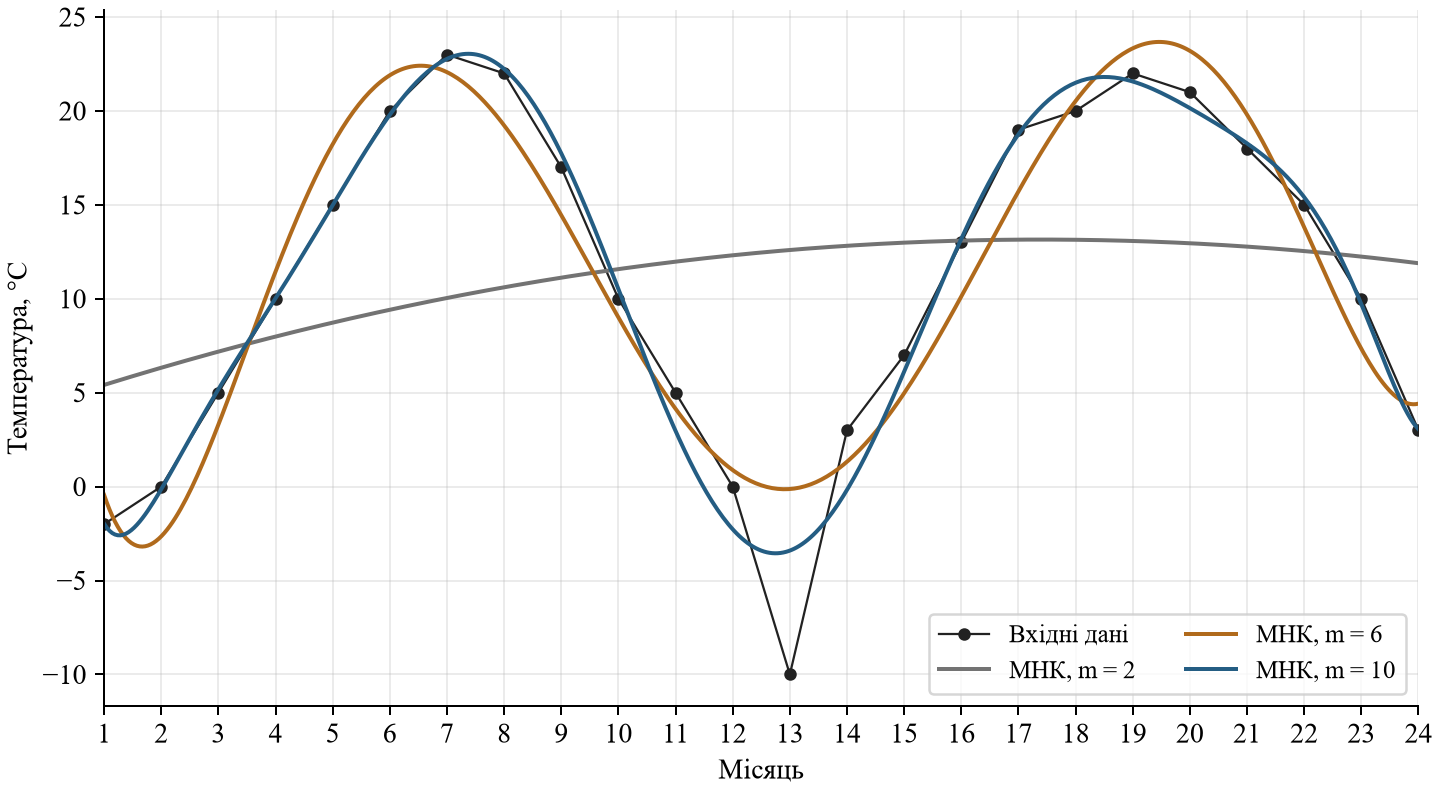

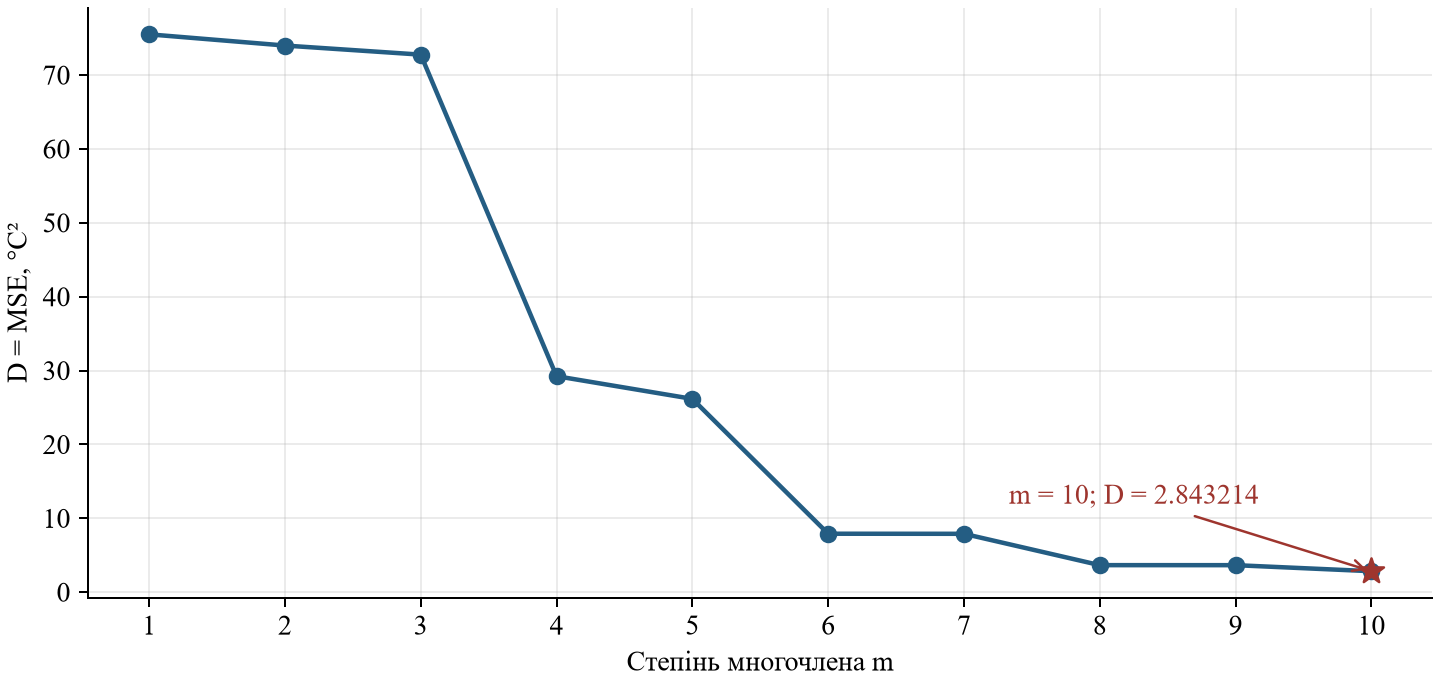

In [3]:
display(Image(filename=str(BASE / "images/approximation.png")))
display(Image(filename=str(BASE / "images/variance.png")))

## 4. Похибки та додаткова табуляція
У відомих вузлах використано $\varepsilon_i=|y_i-P_m(x_i)|$. Між вузлами справжня температура не задана, тому істинну похибку обчислити неможливо. Для додаткової табуляції явно обрано кусково-лінійний інтерполянт $L(x)$, а на щільній сітці обчислено $|L(x)-P_m(x)|$.

Вхідна таблиця містить 24 вузли з кроком 1 місяць (23 проміжки). Для щільної сітки за числом $n=24$ із завдання: $h_1=(24-1)/(20\cdot24)=23/480$ місяця, **481 точка**. Повні значення для всіх m=1..10 збережено у `processed/dense_errors.csv`; вузлові похибки - у `processed/node_errors.csv`.

Число точок щільної сітки: 481
h1 = 0.047916666667 місяця


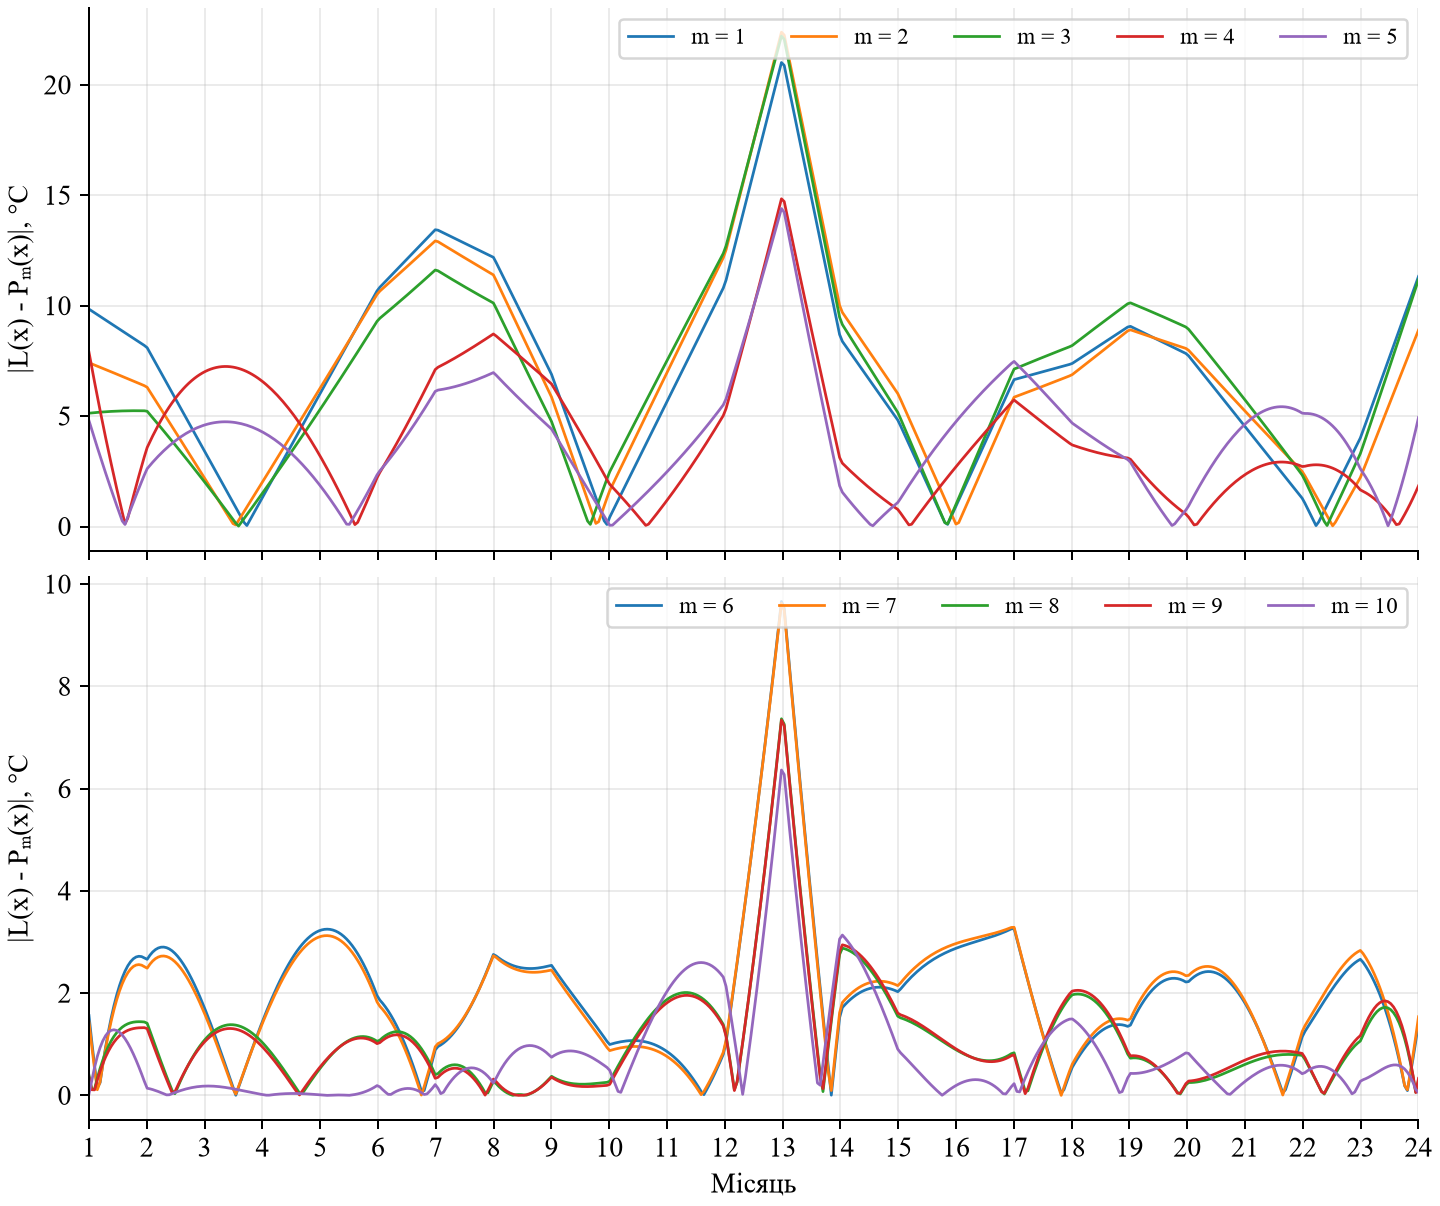

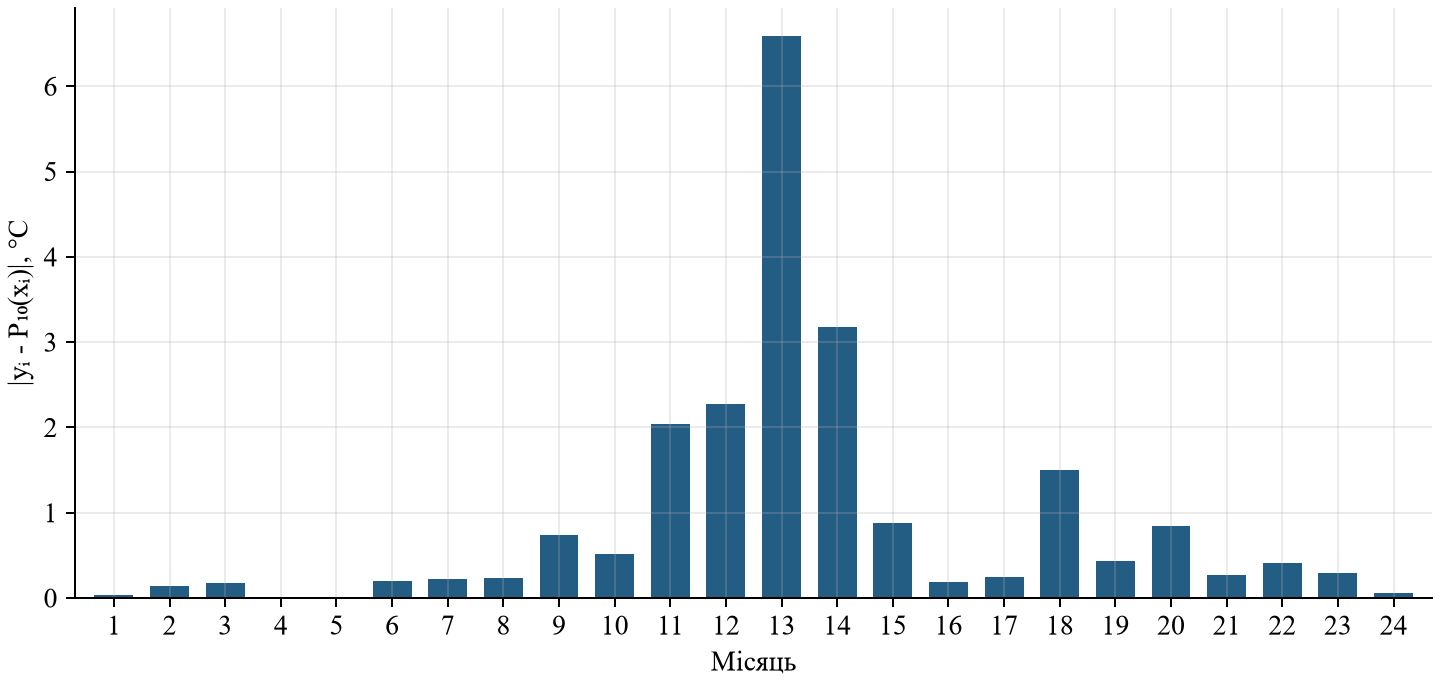

In [4]:
print(f"Число точок щільної сітки: {len(result['grid'])}")
print(f"h1 = {result['grid_step']:.12f} місяця")
display(Image(filename=str(BASE / "images/errors_all_degrees.png")))
display(Image(filename=str(BASE / "images/node_errors.png")))

## 5. Формальна екстраполяція
Обчислюємо той самий поліном $P_{10}$ для місяців 25, 26 і 27. Результати є математичною екстраполяцією; високий степінь і вихід за межі даних призводять до непридатних для реальної температури значень. Такий алгоритм не є надійним метеорологічним прогнозом.

Місяць 25: 16.217677348 °C
Місяць 26: 121.854748296 °C
Місяць 27: 506.319851298 °C


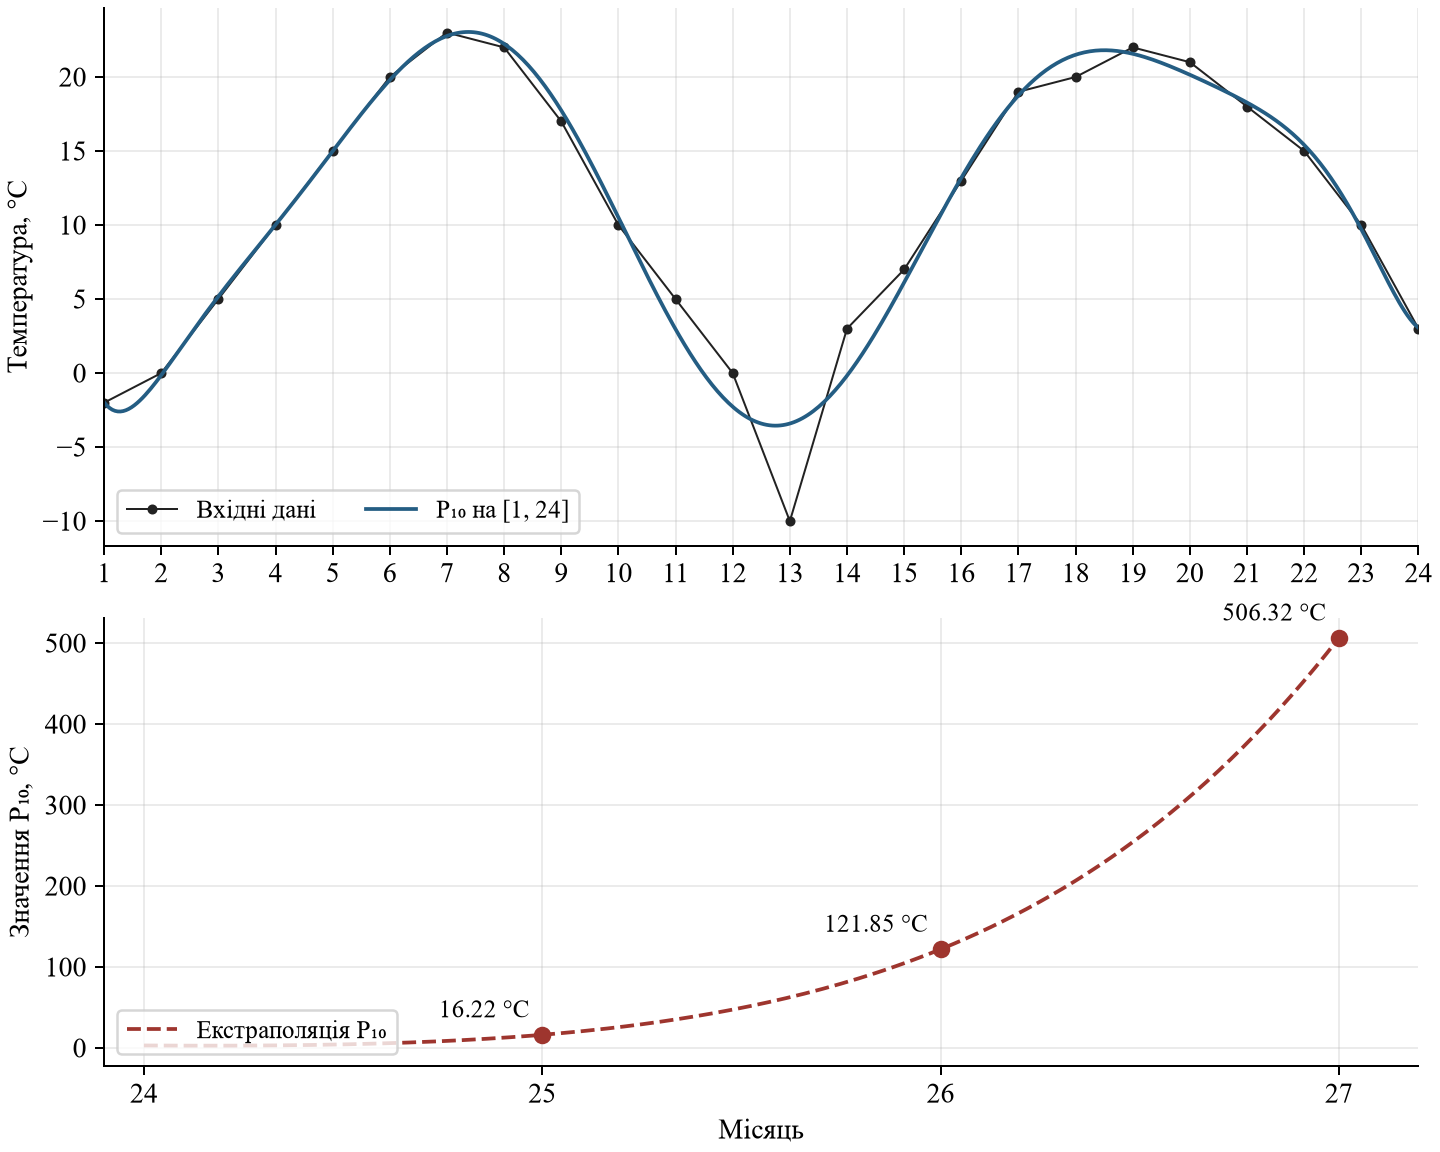

In [5]:
for month, value in zip(result["future_months"], optimal["forecast"]):
    print(f"Місяць {month:.0f}: {value:.9f} °C")
display(Image(filename=str(BASE / "images/forecast.png")))

## 6. Перевірка чисельного розв’язку
Як незалежну перевірку порівнюємо власний розв’язок нормальної системи з `numpy.linalg.lstsq`, застосованим безпосередньо до матриці значень базисних функцій. Бібліотечний розв’язувач використовується лише в цій перевірці, а не для результатів лабораторної.

In [6]:
grid_t = (np.asarray(result["grid"]) - result["center"]) / result["scale"]
max_difference = 0.0
for model in result["models"]:
    design = np.vander(t, model["degree"] + 1, increasing=True)
    reference_coef = np.linalg.lstsq(design, y, rcond=None)[0]
    difference = float(np.max(np.abs(polynomial(grid_t, np.array(model["coef_t"])) - polynomial(grid_t, reference_coef))))
    max_difference = max(max_difference, difference)
    assert difference < 1e-6
print(f"Найбільша різниця між значеннями поліномів на щільній сітці: {max_difference:.3e} °C")
print("Усі 10 моделей пройшли перевірку.")

Найбільша різниця між значеннями поліномів на щільній сітці: 1.518e-10 °C
Усі 10 моделей пройшли перевірку.


## Висновки
Реалізовано читання CSV, формування нормальних рівнянь, власний метод Гауса з вибором головного елемента, схему Горнера та обчислення похибок. Серед степенів 1..10 найменшу MSE має $m=10$: 2.843214070 °C², RMSE - 1.686183285 °C. Найскладніша для апроксимації точка - місяць 13, похибка 6.593893927 °C. Похибки всіх моделей протабульовано у вузлах і на щільній сітці з явно зазначеним інтерполяційним припущенням. Формальна екстраполяція дала 16.217677, 121.854748 і 506.319851 °C, що демонструє нестійкість високого полінома поза навчальним відрізком. Результати власного алгоритму узгоджуються з незалежним бібліотечним розв’язком.